In [1]:
# path setup (scripts/nb_layout.py): run from the folder this notebook belongs to, with scripts/ importable
import os, sys
if '_HHS_ROOT' not in globals():
    _d = os.getcwd()
    while os.path.basename(_d) != 'notebooks' and os.path.dirname(_d) != _d:
        _d = os.path.dirname(_d)
    _HHS_ROOT = os.path.dirname(_d) if os.path.basename(_d) == 'notebooks' else os.getcwd()
    os.chdir(os.path.join(_HHS_ROOT, '.'))
    sys.path[:0] = [os.path.join(_HHS_ROOT, 'scripts'), os.getcwd()]

# R4 + C + fallback: the leader fallback with the blind helper

**The arm.** R4+C (`R4_bsc`): the leader sends the first copy, every later reserved slot of the TB is handed to the
Kuo helper, which relays a decoded TB blindly in each of them; receivers soft-combine the copies. No HARQ feedback.
**R4 + C + fallback** (`R4_bsc_fb`, `--blindHelperFallback=true`) adds R6's fallback: after each of its own
transmissions the leader listens in the helper's next handed slot; if it decodes no SCI of the helper there (the
helper missed the TB), it takes back the following handed slot and retransmits itself (`_ltx.csv` origin 2). Without
feedback this is the only takeover; R6 also takes over on a helper NACK and stops on all-ACK.

**Question.** How much of R6's gain over R4+C is the takeover alone, and what does it cost?

**Data.** `out/remote_v3_fb` (campaign `v3_fb`, 300 runs) and `out/remote_v3` (R4_bsc, R6): 3 routes × 2 traffic types
× 0 / 15 / 30 / 45 / 60 background vehicles × 10 seeds; the commands differ only in the new flag, so runs pair by
seed. Intervals: 95 % Student-t over the paired differences; `*` = excludes 0.

In [2]:
import glob, os, re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import plot_prr_vs_cbr as P
FIG = 'figures/r4c_fallback'; os.makedirs(FIG, exist_ok=True)
NBG = {'none': 0, 'n15': 15, 'n30': 30, 'n45': 45, 'moderate': 60}
COLS = ['prr_mean', 'prr_min', 'tx_per_pkt', 'cbr_occupied', 'pkts', 'leader_tx', 'helper_tx', 'relay_sent',
        'fallback_check', 'fallback_heard', 'fallback_tx', 'fallback_no_slot', 'fallback_late', 'fallback_late_no_slot',
        'helper_assigned', 'helper_decoded', 'helper_sci_missed', 'res_used_leader', 'res_used_helper',
        'leader_fallback']
def load(folder, arm):
    rows = []
    for f in glob.glob(f'out/{folder}/{arm}/*_run.csv*'):
        sc, _, tr, bg, s = os.path.basename(f).split('_run.csv')[0].split('_')
        r = pd.read_csv(f).iloc[0]
        rows.append({k: r[k] for k in COLS if k in r} | dict(arm=arm, sc=sc, tr=tr, nbg=NBG[bg], seed=int(s[1:])))
    return pd.DataFrame(rows)
fb = load('remote_v3_fb', 'R4_bsc_fb')
ref = pd.concat([load('remote_v3', 'R4_bsc'), load('remote_v3', 'R6')])
assert len(fb), 'no R4_bsc_fb runs in out/remote_v3_fb: copy the campaign first'
print(len(fb), 'R4 + C + fallback runs;', fb.groupby(['sc', 'tr', 'nbg']).size().describe()[['min', 'max']].to_dict(),
      'seeds per cell; leader_fallback flag', sorted(fb.leader_fallback.unique()))
K = ['sc', 'tr', 'nbg', 'seed']
J = fb.merge(ref[ref.arm == 'R4_bsc'], on=K, suffixes=('', '_r4')).merge(ref[ref.arm == 'R6'], on=K, suffixes=('', '_r6'))
J['cbr'] = J.cbr_occupied
print(len(J), 'paired runs')
def ci(x):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    m = x.mean(); h = stats.t.ppf(.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan
    return m, h
def fmt(x, f=1):
    m, h = ci(f * x); return f'{m:+.2f} ± {h:.2f}' + ('*' if abs(m) > h else ' ')

300 R4 + C + fallback runs; {'min': 10.0, 'max': 10.0} seeds per cell; leader_fallback flag [np.int64(1)]
300 paired runs


## 1. Fallback activity

Per packet: fallback checks (a handed slot was watched), checks where the helper's SCI was heard, takeovers (the
leader sent in the next handed slot), checks with no handed slot left, and late checks; helper SCI misses as a
share of TBs. Mean over seeds.

In [3]:
A = fb.assign(**{c + '/pkt': fb[c] / fb.pkts for c in ['fallback_check', 'fallback_heard', 'fallback_tx',
                                                      'fallback_no_slot', 'fallback_late']},
              helper_relays_pkt=fb.helper_tx / fb.pkts, leader_tx_pkt=fb.leader_tx / fb.pkts)
cols = [c for c in A.columns if c.endswith('/pkt') or c.endswith('_pkt')]
with pd.option_context('display.max_rows', 100):
    display(A.groupby(['sc', 'tr', 'nbg'])[cols].mean().round(3))

tx_per_pkt  fallback_check/pkt  fallback_heard/pkt  \
sc   tr           nbg                                                       
hwy  aperiodic1tb 0         2.895               1.026               0.919   
                  15        2.859               1.025               0.851   
                  30        2.799               1.024               0.777   
                  45        2.731               1.025               0.693   
                  60        2.593               1.024               0.548   
     periodic1tb  0         2.921               1.024               0.949   
                  15        2.926               1.024               0.942   
                  30        2.925               1.024               0.942   
                  45        2.885               1.024               0.876   
                  60        2.857               1.024               0.863   
rbt  aperiodic1tb 0         2.809               1.721               1.511   
                  15        2.806               1.727               1.493   
                  30        2.771               1.712               1.395   
                  45        2.709               2.196               1.577   
                  60        2.676               1.988               1.357   
     periodic1tb  0         2.930               1.717               1.637   
                  15        2.926               1.713               1.624   
                  30        2.934               1.737               1.632   
                  45        2.902               2.168               1.960   
                  60        2.891               1.991               1.784   
rbtE aperiodic1tb 0         2.891               1.515               1.388   
                  15        2.851               1.519               1.334   
                  30        2.828               1.519               1.274   
                  45        2.768               1.870               1.387   
                  60        2.685               1.718               1.169   
     periodic1tb  0         2.948               1.512               1.454   
                  15        2.942               1.511               1.440   
                  30        2.928               1.533               1.443   
                  45        2.909               1.853               1.698   
                  60        2.888               1.720               1.548   

                       fallback_tx/pkt  fallback_no_slot/pkt  \
sc   tr           nbg                                          
hwy  aperiodic1tb 0              0.096                 0.010   
                  15             0.158                 0.016   
                  30             0.219                 0.028   
                  45             0.300                 0.033   
                  60             0.418                 0.058   
     periodic1tb  0              0.060                 0.015   
                  15             0.075                 0.006   
                  30             0.077                 0.005   
                  45             0.137                 0.012   
                  60             0.143                 0.019   
rbt  aperiodic1tb 0              0.186                 0.024   
                  15             0.207                 0.027   
                  30             0.286                 0.032   
                  45             0.558                 0.062   
                  60             0.559                 0.073   
     periodic1tb  0              0.069                 0.011   
                  15             0.083                 0.006   
                  30             0.101                 0.004   
                  45             0.199                 0.009   
                  60             0.193                 0.014   
rbtE aperiodic1tb 0              0.113                 0.013   
                  15             0.165                 0.020   
                  30  

## 2. Takeover gain: R4 + C + fallback − R4+C (paired by seed)

Group PRR (pp), worst-member PRR (pp), transmissions per packet (leader + helper).

In [4]:
rows = []
for (sc, tr, n), q in J.groupby(['sc', 'tr', 'nbg']):
    rows.append({'route': P.SCN[sc], 'traffic': P.TRN[tr], 'bg': n, 'CBR (%)': round(100 * q.cbr.mean()),
                 'Δ prr_mean (pp)': fmt(q.prr_mean - q.prr_mean_r4, 100),
                 'Δ prr_min (pp)': fmt(q.prr_min - q.prr_min_r4, 100),
                 'Δ tx/pkt': fmt(q.tx_per_pkt - q.tx_per_pkt_r4)})
G = pd.DataFrame(rows).set_index(['route', 'traffic', 'bg'])
with pd.option_context('display.max_rows', 100):
    display(G)

CBR (%) Δ prr_mean (pp)  Δ prr_min (pp)  \
route        traffic   bg                                            
Highway      aperiodic 0         1   +2.29 ± 0.91*   +6.29 ± 3.71*   
                       15       24   +5.01 ± 0.87*   +6.39 ± 2.17*   
                       30       43   +7.85 ± 1.36*   +9.33 ± 4.01*   
                       45       59  +11.50 ± 1.56*  +10.76 ± 1.91*   
                       60       70  +10.63 ± 1.00*   +7.92 ± 2.66*   
             periodic  0         1   +1.24 ± 0.61*   +4.67 ± 2.63*   
                       15       24   +2.26 ± 1.36*   +6.24 ± 3.08*   
                       30       43   +2.53 ± 1.06*   +5.53 ± 2.59*   
                       45       59   +5.12 ± 1.66*   +8.15 ± 2.85*   
                       60       70   +5.24 ± 1.10*   +7.32 ± 2.30*   
Roundabout W aperiodic 0         1   +0.60 ± 1.77    -0.52 ± 3.11    
                       15       23   +3.27 ± 2.61*   +1.40 ± 4.17    
                       30       42   +4.41 ± 2.02*   +1.79 ± 3.05    
                       45       58   +5.20 ± 2.34*   -2.14 ± 3.53    
                       60       69   +6.10 ± 1.94*   +1.62 ± 2.54    
             periodic  0         1   +0.36 ± 1.44    -0.88 ± 2.92    
                       15       23   +0.54 ± 1.92    -1.04 ± 4.08    
                       30       42   +2.31 ± 1.67*   +3.30 ± 3.57    
                       45       58   +1.53 ± 1.84    +1.11 ± 3.76    
                       60       69   +1.37 ± 2.11    -0.75 ± 3.23    
Roundabout E aperiodic 0         1   +0.86 ± 1.64    +0.26 ± 3.24    
                       15       23   +3.01 ± 1.35*   +2.13 ± 2.60    
                       30       42   +3.40 ± 1.93*   +0.75 ± 2.80    
                       45       58   +5.54 ± 2.05*   +2.03 ± 2.07    
                       60       69   +6.00 ± 1.68*   +0.97 ± 1.85    
             periodic  0         1   +1.16 ± 1.07*   +1.56 ± 3.29    
                       15       23   +1.03 ± 0.93*   -2.10 ± 2.57    
                       30       42   +2.46 ± 3.43    +1.36 ± 4.25    
                       45       58   +2.75 ± 1.99*   +1.53 ± 3.72    
                       60       69   +3.63 ± 3.07*   +2.62 ± 4.16    

                                Δ tx/pkt  
route        traffic   bg                 
Highway      aperiodic 0   +0.10 ± 0.05*  
                       15  +0.15 ± 0.02*  
                       30  +0.23 ± 0.05*  
                       45  +0.33 ± 0.05*  
                       60  +0.39 ± 0.04*  
             periodic  0   +0.06 ± 0.04*  
                       15  +0.09 ± 0.04*  
                       30  +0.08 ± 0.04*  
                       45  +0.15 ± 0.06*  
                       60  +0.13 ± 0.05*  
Roundabout W aperiodic 0   +0.10 ± 0.03*  
                       15  +0.17 ± 0.06*  
                       30  +0.20 ± 0.04*  
                       45  +0.26 ± 0.06*  
                       60  +0.29 ± 0.05*  
             periodic  0   +0.03 ± 0.03*  
                       15  +0.05 ± 0.04*  
                       30  +0.08 ± 0.06*  
                       45  +0.11 ± 0.08*  
                       60  +0.11 ± 0.06*  
Roundabout E aperiodic 0   +0.07 ± 0.03*  
                       15  +0.15 ± 0.04*  
                       30  +0.13 ± 0.05*  
                       45  +0.23 ± 0.04*  
                       60  +0.27 ± 0.05*  
             periodic  0   +0.05 ± 0.03*  
                       15  +0.06 ± 0.02*  
                       30  +0.08 ± 0.08   
                       45  +0.09 ± 0.05*  
                       60  +0.11 ± 0.08*

## 3. What is left to R6: R6 − R4 + C + fallback (paired by seed)

The part of R6's gain over R4+C that the fallback alone does not give: feedback-driven relaying (stop on all-ACK),
takeover on a helper NACK, and Option 2 retransmissions.

In [5]:
rows = []
for (sc, tr, n), q in J.groupby(['sc', 'tr', 'nbg']):
    t6 = q.prr_mean_r6 - q.prr_mean_r4
    rows.append({'route': P.SCN[sc], 'traffic': P.TRN[tr], 'bg': n,
                 'R6 − R4+C (pp)': fmt(t6, 100),
                 'R6 − R4+C+fb (pp)': fmt(q.prr_mean_r6 - q.prr_mean, 100),
                 'share of R6 gain from fallback (%)': round(100 * (q.prr_mean - q.prr_mean_r4).mean() / t6.mean())
                 if abs(t6.mean()) > 1e-3 else np.nan,
                 'R6 − R4+C+fb worst (pp)': fmt(q.prr_min_r6 - q.prr_min, 100),
                 'R6 − R4+C+fb tx/pkt': fmt(q.tx_per_pkt_r6 - q.tx_per_pkt)})
with pd.option_context('display.max_rows', 100):
    display(pd.DataFrame(rows).set_index(['route', 'traffic', 'bg']))

R6 − R4+C (pp) R6 − R4+C+fb (pp)  \
route        traffic   bg                                     
Highway      aperiodic 0    +2.71 ± 1.16*     +0.41 ± 0.36*   
                       15   +6.57 ± 1.00*     +1.56 ± 0.41*   
                       30  +10.15 ± 1.24*     +2.30 ± 0.43*   
                       45  +15.25 ± 2.03*     +3.74 ± 1.04*   
                       60  +17.32 ± 2.57*     +6.70 ± 2.13*   
             periodic  0    +1.62 ± 0.81*     +0.38 ± 0.47    
                       15   +2.43 ± 1.55*     +0.17 ± 0.29    
                       30   +2.84 ± 1.16*     +0.31 ± 0.36    
                       45   +6.14 ± 1.98*     +1.02 ± 0.74*   
                       60   +6.64 ± 1.84*     +1.40 ± 0.94*   
Roundabout W aperiodic 0    +4.44 ± 2.08*     +3.83 ± 2.41*   
                       15   +7.39 ± 1.69*     +4.12 ± 2.47*   
                       30   +7.59 ± 1.36*     +3.18 ± 0.94*   
                       45   +9.49 ± 2.92*     +4.29 ± 2.02*   
                       60  +10.74 ± 1.63*     +4.64 ± 2.06*   
             periodic  0    +1.92 ± 0.94*     +1.56 ± 0.73*   
                       15   +2.64 ± 1.74*     +2.10 ± 1.77*   
                       30   +3.05 ± 1.22*     +0.75 ± 1.81    
                       45   +2.99 ± 1.03*     +1.47 ± 1.70    
                       60   +3.86 ± 2.19*     +2.49 ± 2.09*   
Roundabout E aperiodic 0    +3.25 ± 1.58*     +2.39 ± 1.21*   
                       15   +6.55 ± 1.86*     +3.55 ± 1.32*   
                       30   +6.61 ± 1.01*     +3.20 ± 1.60*   
                       45   +8.96 ± 1.77*     +3.42 ± 1.58*   
                       60  +12.32 ± 2.10*     +6.32 ± 1.23*   
             periodic  0    +2.18 ± 0.83*     +1.02 ± 0.80*   
                       15   +2.50 ± 0.74*     +1.46 ± 1.19*   
                       30   +3.31 ± 2.61*     +0.84 ± 1.40    
                       45   +3.71 ± 2.25*     +0.96 ± 1.43    
                       60   +6.02 ± 2.44*     +2.39 ± 1.96*   

                           share of R6 gain from fallback (%)  \
route        traffic   bg                                       
Highway      aperiodic 0                                   85   
                       15                                  76   
                       30                                  77   
                       45                                  75   
                       60                                  61   
             periodic  0                                   76   
                       15                                  93   
                       30                                  89   
                       45                                  83   
                       60                                  79   
Roundabout W aperiodic 0                                   14   
                       15                                  44   
                       30                                  58   
                       45                                  55   
                       60                                  57   
             periodic  0                                   19   
                       15                                  20   
                       30                                  76   
                       45                                  51   
                       60                                  36   
Roundabout E aperiodic 0                                   26   
                       15                                  46   
                       30                                  51   
                       45                                  62   
                       60                                  49   
             periodic  0                                   53   
                       15                                  41   
                       30                                  75   
                       45                                  7

## 4. Against the pool CBR (R3, R4+C, R4 + C + fallback, R6)

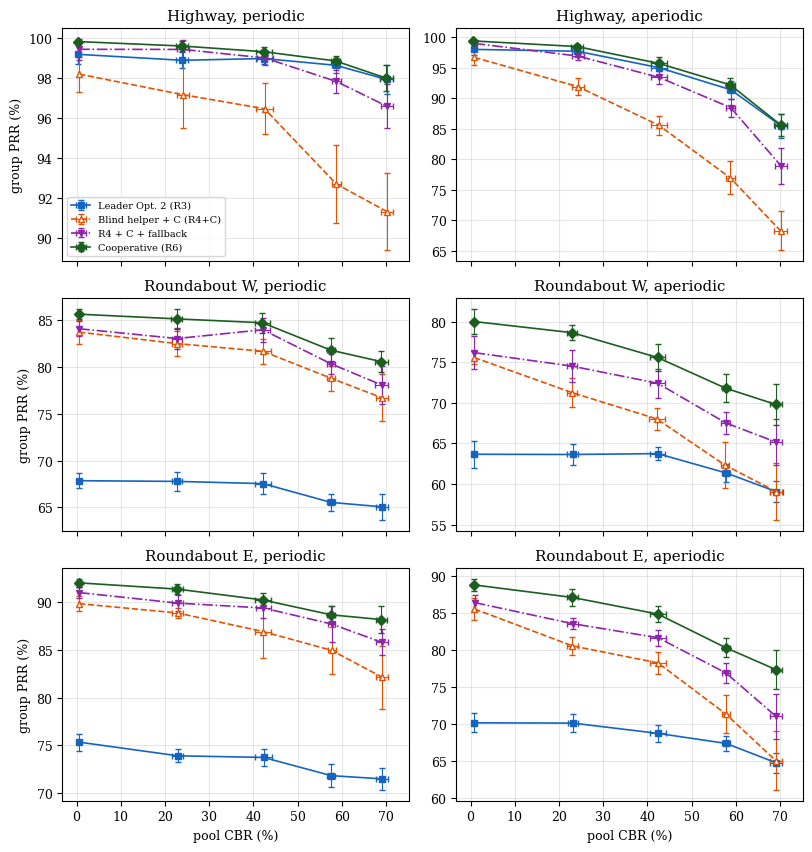

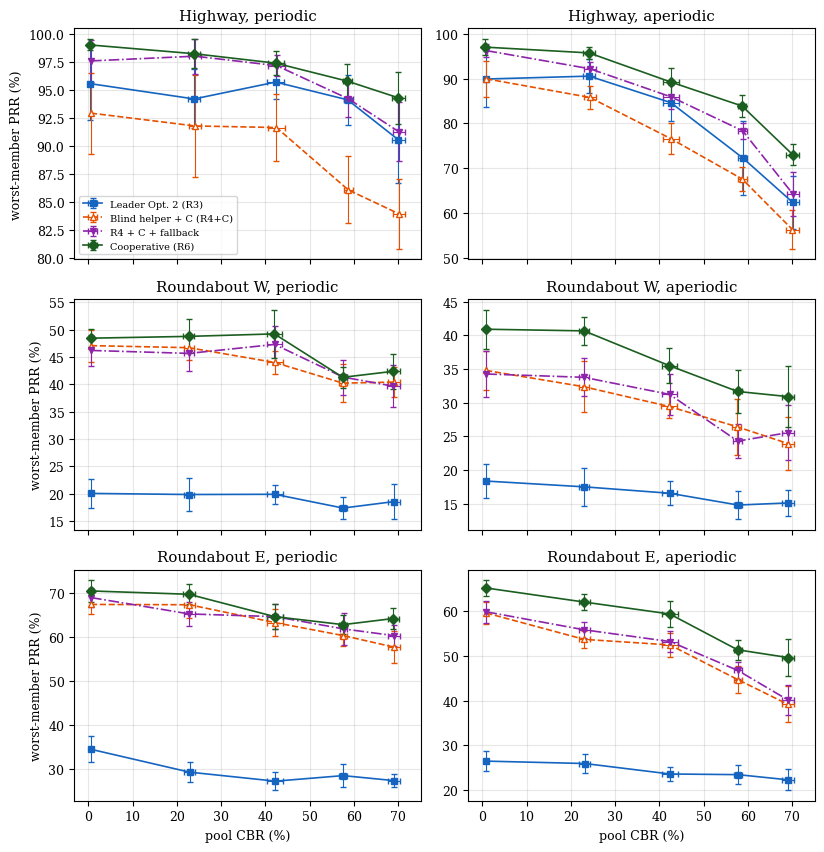

In [6]:
D = P.load(); M = P.means(D)
P.grid(M, 'prr', 'group PRR (%)', None); plt.savefig(f'{FIG}/prr_vs_cbr.pdf'); plt.show()
P.grid(M, 'worst', 'worst-member PRR (%)', None); plt.savefig(f'{FIG}/worst_vs_cbr.pdf'); plt.show()

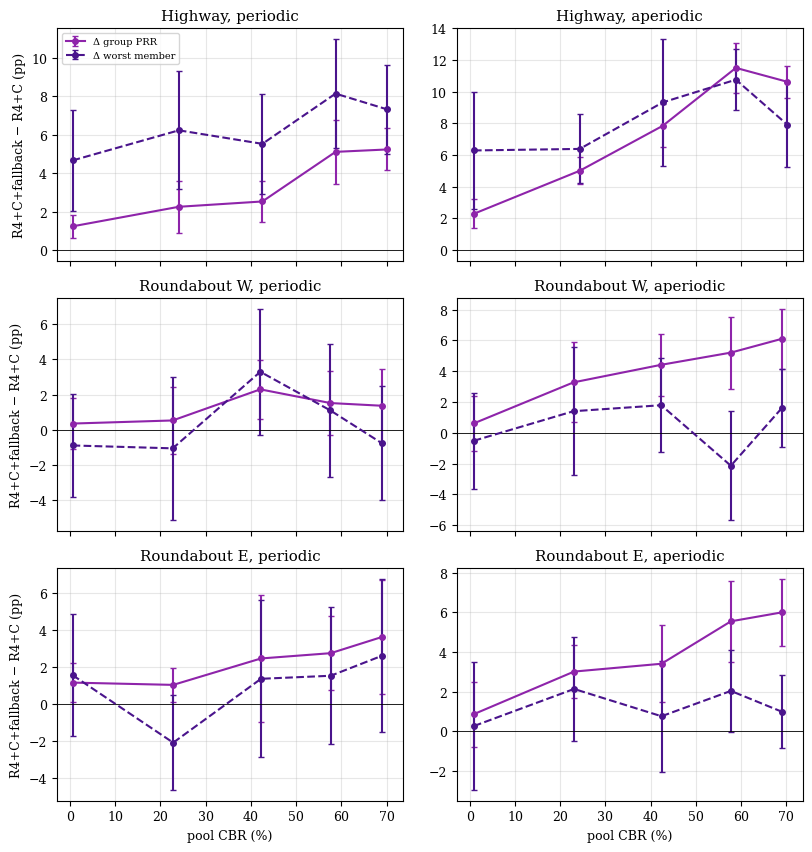

In [7]:
fig, axs = plt.subplots(3, 2, figsize=(8.2, 8.6), sharex=True)
for i, sc in enumerate(P.SCN):
    for j, tr in enumerate(P.TRN):
        a = axs[i, j]
        for k, f, lab, col in [('prr_mean', 100, 'Δ group PRR', '#8e24aa'), ('prr_min', 100, 'Δ worst member', '#4a148c')]:
            pts = [(100 * q.cbr.mean(), *ci(f * (q[k] - q[k + '_r4']))) for n, q in
                   J[(J.sc == sc) & (J.tr == tr)].groupby('nbg')]
            x, m, h = map(np.array, zip(*pts))
            a.errorbar(x, m, yerr=h, marker='o', ms=4, capsize=2, color=col, label=lab, ls='-' if k == 'prr_mean' else '--')
        a.axhline(0, color='k', lw=.6); a.grid(alpha=.3); a.set_title(f'{P.SCN[sc]}, {P.TRN[tr]}')
        if i == 2: a.set_xlabel('pool CBR (%)')
        if j == 0: a.set_ylabel('R4+C+fallback − R4+C (pp)')
axs[0, 0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(f'{FIG}/fallback_gain_vs_cbr.pdf'); plt.show()

## 5. Findings

Campaign `v3_fb` (commit 3d66267): 300 / 300 runs, 10 seeds per cell, `leader_fallback` = 1 in every run.

**The takeover gain (R4 + C + fallback − R4+C).**
- The fallback never hurts the group PRR, and the gain grows with the load. **Highway:** +2.3 pp (aperiodic) and
  +1.2 pp (periodic) at 0 vehicles, rising to +10.6 / +5.2 pp at CBR 0.70. **Roundabouts, aperiodic:** +0.6 to
  +0.9 pp (not significant) at 0 vehicles, +6.0 / +6.1 pp at CBR 0.70. **Roundabouts, periodic:** at most +3.6 pp,
  and on W it is significant only at 30 vehicles.
- The load makes the helper miss more TBs, so the leader takes over more often. On the highway, aperiodic,
  takeovers per packet rise from 0.10 at 0 vehicles to 0.42 at 60, and the share of checks in which the helper is
  heard falls from 90 % to 54 %. The fallback mends exactly the losses that make R4+C the most load-sensitive scheme.
- **Worst member:** clear gains on the highway (+4.7 to +10.8 pp, every load significant). On the roundabouts the
  change is within ±3.3 pp and never significant. A likely reason: the blocked member does not hear the leader's
  own copy either, so taking the slot back does not help it.
- **Cost:** +0.03 to +0.39 transmissions per packet, growing with the load (largest on the highway, aperiodic).
  R4 + C + fallback uses 2.6–2.9 transmissions per packet against R6's 1.7–2.7. R6 is cheaper everywhere, except
  with aperiodic traffic on roundabout W at 45–60 vehicles and on E at 60, where the two are equal within the
  interval.

**How much of R6's gain over R4+C the fallback alone gives.**
- **Highway:** most of it, 61–93 %. At CBR 0.70 the fallback closes 10.6 of R6's 17.3 pp (aperiodic) and 5.2 of
  6.6 pp (periodic). With periodic traffic and up to 30 vehicles, what is left to R6 is not significant.
- **Roundabouts:** less, 14–76 %, and only 14–53 % at 0 vehicles. R6 stays significantly ahead with aperiodic
  traffic at every load (+2.4 to +6.3 pp in group PRR, +4.3 to +9.5 pp in the worst member).
- What the fallback does not give is the feedback. R6 retransmits only on a NACK and stops on an all-ACK, which
  saves transmissions where the channel is good; the remaining worst-member gap suggests it also serves the
  blocked members better.

**Against R3.**
- On the roundabouts R4 + C + fallback beats R3 at every CBR (65.2 vs 59.1 % W, 71.1 vs 64.8 % E at CBR 0.70,
  aperiodic).
- On the highway with aperiodic traffic it still falls below R3 under load (78.9 vs 85.5 % at CBR 0.70). Its blind
  relays still add collisions that R3's Option 2 avoids; R6 matches R3 there (85.6 %).

Fallback checks per packet rise from about 1.7 to 2.0–2.2 on the roundabouts at 45–60 vehicles, and not on the
highway. This is not explained here.